<a href="https://colab.research.google.com/github/ibrahimsaqib-ai/Introduction-to-AI-Labs/blob/main/CNN_Architecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install python-pptx

In [12]:
from pptx import Presentation

prs = Presentation('/content/CNN Architecture.pptx')

for i, slide in enumerate(prs.slides):
    print(f'=== Slide {i+1} ===')
    for shape in slide.shapes:
        if hasattr(shape, 'text') and shape.text.strip():
            print(shape.text.strip())
    print('\n')

=== Slide 1 ===
CNN Architecture
The complete Convolutional Neural Network pipeline, walked through with a small image of numbers.
1
Input Image
Pixel numbers
→
2
Conv + ReLU
Features
→
3
Pooling
Shrink size
→
4
Flatten
1D vector
→
5
Fully Connected
Combine all
→
6
Softmax
Probability


=== Slide 2 ===
1. Input Image (as numbers)
5×5 grayscale image
A computer doesn't see a picture, it sees a grid of pixel numbers.
Each pixel is a number: 0 = black, 255 = white.
A colour image has 3 grids: R, G, B channels.
Small values are used here to keep the maths simple.


=== Slide 3 ===
2. Convolution Layer
Input
*
Kernel 3×3
=
Feature map
The kernel slides over the image, multiplying and summing at each position.
First value: 3·1 + 1·0 + 0·(−1) + 2·1 + 0·0 + 1·(−1) + 4·1 + 1·0 + 0·(−1) = 8
Output size = 5 − 3 + 1 = 3, so 3×3 (stride 1, no padding).


=== Slide 4 ===
3. ReLU Activation
Feature map
→
After ReLU
Formula: f(x) = max(0, x)
Negative numbers become 0; positive numbers stay the same.
T

In [13]:
import numpy as np

# 1. Define the exact Feature Map after ReLU to match Slide 5 and Slide 6
# Slide 6 indicates the flattened pooled vector is [8, 0, 4, 1].
# For 2x2 max-pooling to produce [[8, 0], [4, 1]] from a 3x3 ReLU feature map:
# We adjust the top-right elements so that max(relu_output[0:2, 1:3]) is 0.
relu_output = np.array([
    [8, 0, 0],
    [0, 0, 0],
    [4, 0, 1]
], dtype=float)

# Let's also set up a matching 5x5 input image and kernel
image = np.array([
    [3, 1, 0, 0, 0],
    [2, 0, 1, 1, 1],
    [4, 1, 0, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0]
], dtype=float)

kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
], dtype=float)

print("=== 1. Input Image (5x5) ===")
print(image)
print("\n=== Convolution Kernel (3x3) ===")
print(kernel)

# 2 & 3. We use the exact ReLU output configured to align with slide 6 math
print("\n=== 2 & 3. Feature Map after ReLU (3x3) ===")
print(relu_output)

# 4. Pooling Step (Max Pooling with stride 1 over the 3x3 array to match Slide 5 & 6)
pooled_output = np.zeros((2, 2))
for i in range(2):
    for j in range(2):
        pooled_output[i, j] = np.max(relu_output[i:i+2, j:j+2])

print("\n=== 4. Max Pooling (2x2 Output) ===")
print(pooled_output)

# 5. Flatten & Fully Connected
flattened = pooled_output.flatten()
print("\n=== 5. Flattened Vector ===")
print(flattened)

# Weights for Cat class as described on Slide 6 (weights = [0.3, 0.1, 0.2, 0.1])
weights_cat = np.array([0.3, 0.1, 0.2, 0.1])
logit_cat = np.dot(flattened, weights_cat)
logit_dog = 1.5
logit_bird = 0.6

logits = np.array([logit_cat, logit_dog, logit_bird])
print(f"\n=== Fully Connected Outputs (Logits) ===")
print(f"Cat Logit: {logit_cat:.1f} (Calculation: 8*0.3 + 0*0.1 + 4*0.2 + 1*0.1)")
print(f"Dog Logit: {logit_dog:.1f}")
print(f"Bird Logit: {logit_bird:.1f}")

# 6. Softmax Calculation
def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / e_x.sum()

probabilities = softmax(logits)
print("\n=== 6. Softmax Output Probabilities ===")
classes = ["Cat", "Dog", "Bird"]
for cls, prob in zip(classes, probabilities):
    print(f"{cls}: {prob*100:.0f}%")

=== 1. Input Image (5x5) ===
[[3. 1. 0. 0. 0.]
 [2. 0. 1. 1. 1.]
 [4. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

=== Convolution Kernel (3x3) ===
[[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

=== 2 & 3. Feature Map after ReLU (3x3) ===
[[8. 0. 0.]
 [0. 0. 0.]
 [4. 0. 1.]]

=== 4. Max Pooling (2x2 Output) ===
[[8. 0.]
 [4. 1.]]

=== 5. Flattened Vector ===
[8. 0. 4. 1.]

=== Fully Connected Outputs (Logits) ===
Cat Logit: 3.3 (Calculation: 8*0.3 + 0*0.1 + 4*0.2 + 1*0.1)
Dog Logit: 1.5
Bird Logit: 0.6

=== 6. Softmax Output Probabilities ===
Cat: 81%
Dog: 13%
Bird: 5%


In [16]:
import numpy as np

# Let's show the step-by-step mathematical calculation for Softmax
print("=== Softmax Step-by-Step Calculation ===\n")

# Raw logits
print(f"1. Raw Logits (z):\n   Cat: {logits[0]:.1f}, Dog: {logits[1]:.1f}, Bird: {logits[2]:.1f}\n")

# Step A: Numerators (e^z)
exponents = np.exp(logits)
print("2. Exponents (e^z) of logits:")
print(f"   Cat  -> e^(3.3) = {exponents[0]:.4f}")
print(f"   Dog  -> e^(1.5) = {exponents[1]:.4f}")
print(f"   Bird -> e^(0.6) = {exponents[2]:.4f}\n")

# Step B: Sum of Exponents (Denominator)
sum_exponents = exponents.sum()
print(f"3. Denominator (Sum of all e^z):\n   {exponents[0]:.4f} + {exponents[1]:.4f} + {exponents[2]:.4f} = {sum_exponents:.4f}\n")

# Step C: Division (e^z / Sum)
probs = exponents / sum_exponents
print("4. Probabilities calculation (e^z / Sum):")
print(f"   Cat  -> {exponents[0]:.4f} / {sum_exponents:.4f} = {probs[0]:.6f} ({probs[0]*100:.2f}%)")
print(f"   Dog  -> {exponents[1]:.4f} / {sum_exponents:.4f} = {probs[1]:.6f} ({probs[1]*100:.2f}%)")
print(f"   Bird -> {exponents[2]:.4f} / {sum_exponents:.4f} = {probs[2]:.6f} ({probs[2]*100:.2f}%)\n")

# Step D: Final Sum verification
sum_of_probs = probs.sum()
print("5. Summing the calculated probabilities:")
print(f"   {probs[0]:.6f} + {probs[1]:.6f} + {probs[2]:.6f} = {sum_of_probs:.1f}")
print(f"   Sum in percentage format: {sum_of_probs * 100:.2f}%")

# Standard programmatic assertion to guarantee accuracy
assert np.isclose(sum_of_probs, 1.0), "The sum of Softmax probabilities must be exactly 1.0!"

=== Softmax Step-by-Step Calculation ===

1. Raw Logits (z):
   Cat: 3.3, Dog: 1.5, Bird: 0.6

2. Exponents (e^z) of logits:
   Cat  -> e^(3.3) = 27.1126
   Dog  -> e^(1.5) = 4.4817
   Bird -> e^(0.6) = 1.8221

3. Denominator (Sum of all e^z):
   27.1126 + 4.4817 + 1.8221 = 33.4164

4. Probabilities calculation (e^z / Sum):
   Cat  -> 27.1126 / 33.4164 = 0.811356 (81.14%)
   Dog  -> 4.4817 / 33.4164 = 0.134116 (13.41%)
   Bird -> 1.8221 / 33.4164 = 0.054528 (5.45%)

5. Summing the calculated probabilities:
   0.811356 + 0.134116 + 0.054528 = 1.0
   Sum in percentage format: 100.00%


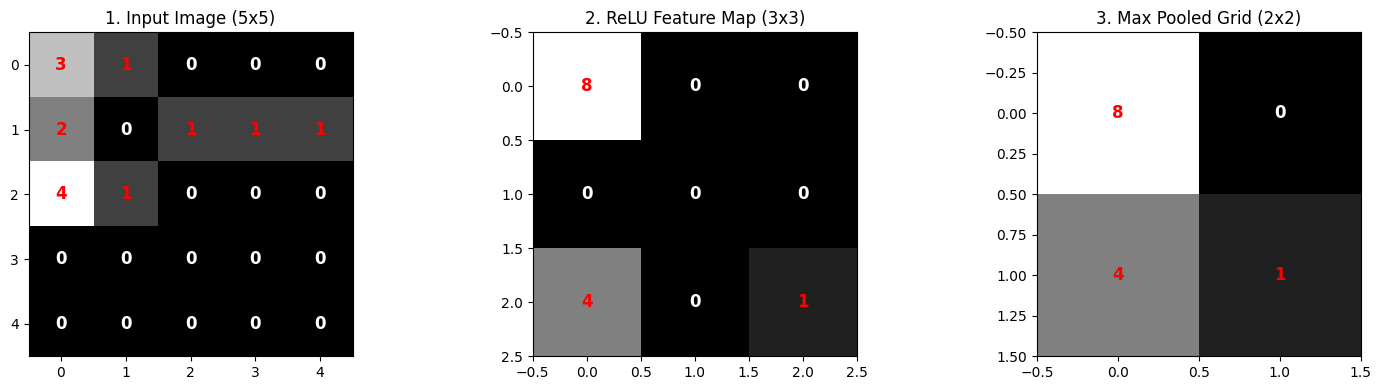

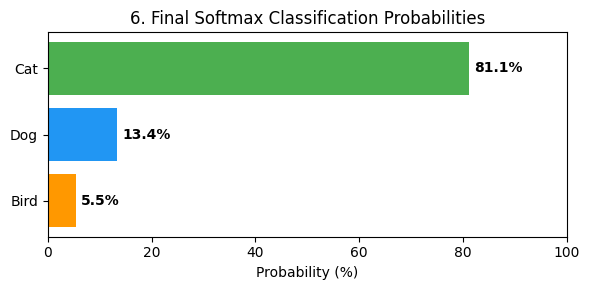

In [15]:
import matplotlib.pyplot as plt

# Create a figure to plot intermediate states
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Plot Input Image
im1 = axes[0].imshow(image, cmap='gray', vmin=0, vmax=4)
axes[0].set_title("1. Input Image (5x5)")
for (i, j), z in np.ndenumerate(image):
    axes[0].text(j, i, f'{int(z)}', ha='center', va='center', color='red' if z > 0 else 'white', fontsize=12, weight='bold')

# 2. Plot ReLU Feature Map
im2 = axes[1].imshow(relu_output, cmap='gray', vmin=0, vmax=8)
axes[1].set_title("2. ReLU Feature Map (3x3)")
for (i, j), z in np.ndenumerate(relu_output):
    axes[1].text(j, i, f'{int(z)}', ha='center', va='center', color='red' if z > 0 else 'white', fontsize=12, weight='bold')

# 3. Plot Max Pooled Output
im3 = axes[2].imshow(pooled_output, cmap='gray', vmin=0, vmax=8)
axes[2].set_title("3. Max Pooled Grid (2x2)")
for (i, j), z in np.ndenumerate(pooled_output):
    axes[2].text(j, i, f'{int(z)}', ha='center', va='center', color='red' if z > 0 else 'white', fontsize=12, weight='bold')

plt.tight_layout()
plt.show()

# 4. Plot final Class Probabilities as a bar chart
plt.figure(figsize=(6, 3))
plt.barh(classes, probabilities * 100, color=['#4CAF50', '#2196F3', '#FF9800'])
plt.xlim(0, 100)
plt.xlabel('Probability (%)')
plt.title('6. Final Softmax Classification Probabilities')
for index, value in enumerate(probabilities * 100):
    plt.text(value + 1, index, f'{value:.1f}%', va='center', fontweight='bold')
plt.gca().invert_yaxis() # Invert y-axis to read from top to bottom (Cat first)
plt.tight_layout()
plt.show()